In [24]:
# ------------------------------------------------------------
# 0. Librerías
# ------------------------------------------------------------
# Se ocultan los avisos de las librerías para que la salida quede más limpia
import warnings
warnings.filterwarnings("ignore")

import os
import copy
import time
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import optuna
from optuna.visualization.matplotlib import plot_optimization_history, plot_param_importances
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms
from torchvision.models import efficientnet_b0, EfficientNet_B0_Weights
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay)

# Semillas para que los resultados sean los mismos en cada ejecución
random.seed(42)
np.random.seed(42)
torch.manual_seed(42)

# Se usa la GPU si existe, si no se usa el CPU
if torch.cuda.is_available():
    DISPOSITIVO = "cuda"
else:
    DISPOSITIVO = "cpu"
print(f"Dispositivo: {DISPOSITIVO}")

Dispositivo: cuda


In [25]:
# ------------------------------------------------------------
# 1. Configuración del componente visual
# ------------------------------------------------------------

# Red preentrenada en ImageNet: EfficientNet-B0
# Se eligió porque es una red ligera (4 millones de parámetros)
ARQUITECTURA = "efficientnet_b0"

# Tamaño al que se amplían las imágenes de 28x28 antes de entrar a la red
TAMANO_IMAGEN = 112

# Número de imágenes para entrenamiento y validación
N_ENTRENAMIENTO = 12000
N_VALIDACION = 3000

# Copias con augmentation que se generan de cada imagen de entrenamiento
COPIAS_AUMENTO = 2

# Entrenamiento de la capa nueva
EPOCAS = 30            # máximo de épocas; el early stopping puede detener antes
PACIENCIA = 5          # épocas sin mejora en la pérdida de validación antes de detener
TAMANO_LOTE = 128      # imágenes por lote al extraer características

# Hiperparámetros iniciales de la capa nueva; después Optuna busca los mejores
PARAMETROS_INICIALES = {
    "tasa_aprendizaje": 0.001,
    "dropout": 0.4,
    "weight_decay": 1e-6,
    "tamano_lote": 128,
}

# Número de combinaciones que prueba Optuna por cada modelo
N_PRUEBAS_OPTUNA = 25

# Clases de Fashion-MNIST
CLASES = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
          "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]

# Prenda del catálogo del chatbot que corresponde a cada clase
CLASE_A_PRENDA = {
    "T-shirt/top": "shirt",
    "Shirt": "shirt",
    "Trouser": "pants",
    "Pullover": "jacket",
    "Coat": "jacket",
    "Dress": "dress",
    "Sandal": "shoes",
    "Sneaker": "shoes",
    "Ankle boot": "shoes",
    "Bag": "accessories",
}

Imágenes de entrenamiento: 60000
Imágenes de prueba: 10000


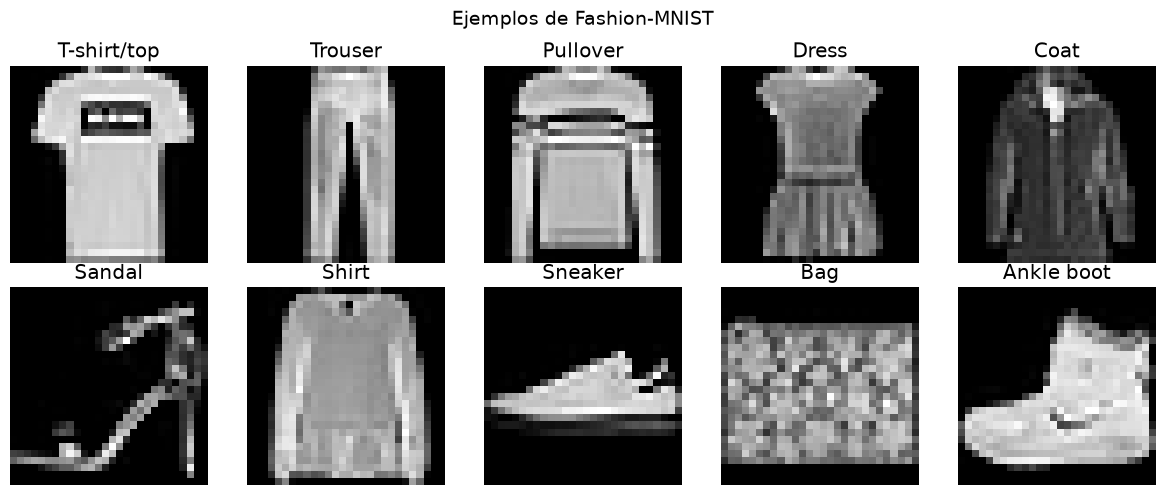

In [26]:
# ------------------------------------------------------------
# 2. Carga de Fashion-MNIST
# ------------------------------------------------------------
# 70,000 imágenes de ropa en escala de grises de 28x28 en 10 clases:
# 60,000 para entrenamiento y 10,000 para prueba

fashion_entrenamiento = datasets.FashionMNIST(root="datos", train=True, download=True)
fashion_prueba = datasets.FashionMNIST(root="datos", train=False, download=True)

etiquetas_entrenamiento = fashion_entrenamiento.targets.numpy()
etiquetas_prueba = fashion_prueba.targets.numpy()

print(f"Imágenes de entrenamiento: {len(fashion_entrenamiento)}")
print(f"Imágenes de prueba: {len(fashion_prueba)}")

# Ejemplo de una imagen de cada clase
plt.figure(figsize=(12, 5))
for clase in range(len(CLASES)):
    indice = np.where(etiquetas_entrenamiento == clase)[0][0]
    imagen, _ = fashion_entrenamiento[indice]

    plt.subplot(2, 5, clase + 1)
    plt.imshow(imagen, cmap="gray")
    plt.title(CLASES[clase])
    plt.axis("off")
plt.suptitle("Ejemplos de Fashion-MNIST", fontsize=14)
plt.tight_layout()
plt.show()

In [27]:
# ------------------------------------------------------------
# 3. División de los datos y análisis de balance
# ------------------------------------------------------------

# Entrenamiento y validación salen del conjunto de entrenamiento con muestreo estratificado,
# de forma que cada clase conserva la misma proporción
indices_entrenamiento, indices_validacion = train_test_split(
    np.arange(len(fashion_entrenamiento)),
    train_size=N_ENTRENAMIENTO,
    test_size=N_VALIDACION,
    stratify=etiquetas_entrenamiento,
    random_state=42
)

# La prueba es el conjunto de prueba original completo
indices_prueba = np.arange(len(fashion_prueba))

y_entrenamiento = etiquetas_entrenamiento[indices_entrenamiento]
y_validacion = etiquetas_entrenamiento[indices_validacion]
y_prueba = etiquetas_prueba[indices_prueba]

# Imágenes por clase en cada conjunto
balance = []
for clase in range(len(CLASES)):
    balance.append({
        "clase": CLASES[clase],
        "entrenamiento_total": (etiquetas_entrenamiento == clase).sum(),
        "entrenamiento": (y_entrenamiento == clase).sum(),
        "validacion": (y_validacion == clase).sum(),
        "prueba": (y_prueba == clase).sum(),
    })

balance = pd.DataFrame(balance)
balance

,clase,entrenamiento_total,entrenamiento,validacion,prueba
0,T-shirt/top,6000,1200,300,1000
1,Trouser,6000,1200,300,1000
2,Pullover,6000,1200,300,1000
3,Dress,6000,1200,300,1000
4,Coat,6000,1200,300,1000
5,Sandal,6000,1200,300,1000
6,Shirt,6000,1200,300,1000
7,Sneaker,6000,1200,300,1000
8,Bag,6000,1200,300,1000
9,Ankle boot,6000,1200,300,1000


Las 10 clases quedan perfectamente balanceadas en los tres conjuntos, con 1,200 imágenes por clase en entrenamiento, 300 en validación y 1,000 en prueba, ya que la división se hizo de forma estratificada. Por esta razón no fue necesario aplicar ninguna técnica para equilibrar las clases, y el data augmentation se usa únicamente para que el modelo aprenda a reconocer variaciones parecidas a las de una foto real.

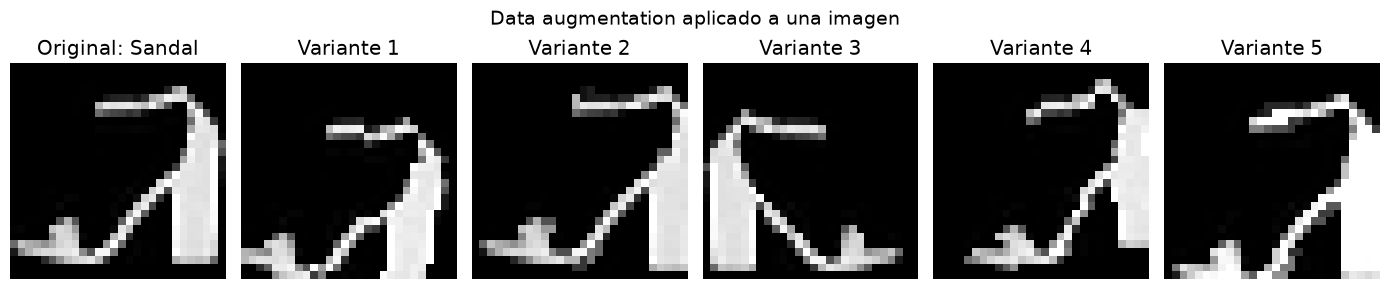

In [28]:
# ------------------------------------------------------------
# 4. Preparación de las imágenes y data augmentation
# ------------------------------------------------------------

# Normalización con las medias y desviaciones de ImageNet, que es como se entrenó la red
MEDIA = [0.485, 0.456, 0.406]
DESVIACION = [0.229, 0.224, 0.225]

# Transformación base: se amplía la imagen, se copia a 3 canales y se normaliza
transformacion_base = transforms.Compose([
    transforms.Resize(TAMANO_IMAGEN),
    transforms.Grayscale(num_output_channels=3),
    transforms.ToTensor(),
    transforms.Normalize(mean=MEDIA, std=DESVIACION),
])

# Data augmentation: como las clases ya están balanceadas, no se usa para equilibrarlas
# sino para que el modelo vea variaciones parecidas a las de una foto real
# (prenda volteada, inclinada, descentrada o con otra iluminación). Solo se usa en entrenamiento.
transformacion_aumento = transforms.Compose([
    transforms.RandomHorizontalFlip(),
    transforms.RandomAffine(degrees=10, translate=(0.1, 0.1), scale=(0.9, 1.1)),
    transforms.ColorJitter(brightness=0.3, contrast=0.3),
    transforms.Resize(TAMANO_IMAGEN),
    transforms.Grayscale(num_output_channels=3),
    transforms.ToTensor(),
    transforms.Normalize(mean=MEDIA, std=DESVIACION),
])

# Versión perturbada de validación y prueba, con variaciones más fuertes,
# para medir qué tan robusto es el modelo ante imágenes menos "perfectas"
transformacion_perturbada = transforms.Compose([
    transforms.RandomHorizontalFlip(),
    transforms.RandomAffine(degrees=15, translate=(0.15, 0.15), scale=(0.85, 1.15)),
    transforms.ColorJitter(brightness=0.4, contrast=0.4),
    transforms.Resize(TAMANO_IMAGEN),
    transforms.Grayscale(num_output_channels=3),
    transforms.ToTensor(),
    transforms.Normalize(mean=MEDIA, std=DESVIACION),
])

# Ejemplo: una imagen original y cinco versiones con augmentation
transformacion_vista = transforms.Compose([
    transforms.RandomHorizontalFlip(),
    transforms.RandomAffine(degrees=10, translate=(0.1, 0.1), scale=(0.9, 1.1)),
    transforms.ColorJitter(brightness=0.3, contrast=0.3),
])

imagen, etiqueta = fashion_entrenamiento[indices_entrenamiento[85]]

plt.figure(figsize=(14, 3))
plt.subplot(1, 6, 1)
plt.imshow(imagen, cmap="gray")
plt.title(f"Original: {CLASES[etiqueta]}")
plt.axis("off")
for i in range(5):
    plt.subplot(1, 6, i + 2)
    plt.imshow(transformacion_vista(imagen), cmap="gray")
    plt.title(f"Variante {i + 1}")
    plt.axis("off")
plt.suptitle("Data augmentation aplicado a una imagen", fontsize=14)
plt.tight_layout()
plt.show()

In [29]:
# ------------------------------------------------------------
# 4.1 Cargadores de datos
# ------------------------------------------------------------

def crear_cargador(entrenamiento, transformacion, indices):
    """
    Crea un DataLoader de Fashion-MNIST con la transformación y las imágenes indicadas.
    """
    datos = datasets.FashionMNIST(root="datos", train=entrenamiento, download=True, transform=transformacion)
    return DataLoader(Subset(datos, indices), batch_size=TAMANO_LOTE, shuffle=False)

cargador_entrenamiento = crear_cargador(True, transformacion_base, indices_entrenamiento)
cargador_entrenamiento_aumento = crear_cargador(True, transformacion_aumento, indices_entrenamiento)
cargador_validacion = crear_cargador(True, transformacion_base, indices_validacion)
cargador_validacion_perturbada = crear_cargador(True, transformacion_perturbada, indices_validacion)
cargador_prueba = crear_cargador(False, transformacion_base, indices_prueba)
cargador_prueba_perturbada = crear_cargador(False, transformacion_perturbada, indices_prueba)

In [30]:
# ------------------------------------------------------------
# 5. CNN con transferencia de aprendizaje: red base congelada
# ------------------------------------------------------------
# La red preentrenada en ImageNet ya sabe reconocer bordes, texturas y formas.
# Se le quita su capa de clasificación original y se congela, de forma que solo
# se usa para convertir cada imagen en un vector de características.

def crear_red_base():
    """
    Carga EfficientNet-B0 preentrenada sin su capa de clasificación y congela sus pesos.
    Devuelve la red y el número de características que produce por imagen.
    """
    red = efficientnet_b0(weights=EfficientNet_B0_Weights.DEFAULT)
    n_caracteristicas = red.classifier[1].in_features
    red.classifier = nn.Identity()

    # Se congelan los pesos para que no se modifiquen al entrenar
    for parametro in red.parameters():
        parametro.requires_grad = False

    red = red.to(DISPOSITIVO)
    red.eval()
    return red, n_caracteristicas

red_base, N_CARACTERISTICAS = crear_red_base()

n_parametros = sum(p.numel() for p in red_base.parameters())
print(f"Red base: {ARQUITECTURA} (congelada)")
print(f"Parámetros de la red base: {n_parametros:,}")
print(f"Características por imagen: {N_CARACTERISTICAS}")

Red base: efficientnet_b0 (congelada)
Parámetros de la red base: 4,007,548
Características por imagen: 1280


In [31]:
# ------------------------------------------------------------
# 6. Extracción de características
# ------------------------------------------------------------
# Cada imagen pasa una sola vez por la red base y se guarda su vector de características
# (la salida del global average pooling). Del entrenamiento se extraen además
# COPIAS_AUMENTO versiones con augmentation, cada una con transformaciones distintas.

def extraer_caracteristicas(cargador, semilla=None):
    """
    Pasa todas las imágenes del cargador por la red base y devuelve sus vectores.
    La semilla fija las transformaciones aleatorias para que se repitan igual.
    """
    if semilla is not None:
        torch.manual_seed(semilla)

    vectores = []
    with torch.no_grad():
        for imagenes, _ in cargador:
            salida = red_base(imagenes.to(DISPOSITIVO))
            vectores.append(salida.cpu())
    return torch.cat(vectores)

inicio = time.time()

X_entrenamiento = extraer_caracteristicas(cargador_entrenamiento)

X_aumento = []
for copia in range(COPIAS_AUMENTO):
    X_aumento.append(extraer_caracteristicas(cargador_entrenamiento_aumento, semilla=100 + copia))

X_validacion = extraer_caracteristicas(cargador_validacion)
X_validacion_perturbada = extraer_caracteristicas(cargador_validacion_perturbada, semilla=123)
X_prueba = extraer_caracteristicas(cargador_prueba)
X_prueba_perturbada = extraer_caracteristicas(cargador_prueba_perturbada, semilla=123)

minutos = (time.time() - inicio) / 60

print("Extracción de características")
print("------------------------")
print(f"Tiempo: {minutos:.1f} minutos")
print(f"Entrenamiento: {X_entrenamiento.shape[0]} imágenes x {X_entrenamiento.shape[1]} características")
print(f"Copias con augmentation: {COPIAS_AUMENTO} de {X_aumento[0].shape[0]} imágenes")
print(f"Validación: {X_validacion.shape[0]} imágenes")
print(f"Prueba: {X_prueba.shape[0]} imágenes")

Extracción de características
------------------------
Tiempo: 0.7 minutos
Entrenamiento: 12000 imágenes x 1280 características
Copias con augmentation: 2 de 12000 imágenes
Validación: 3000 imágenes
Prueba: 10000 imágenes


La extracción de características tomó 0.7 minutos y cada imagen quedó representada por un vector de 1,280 valores, de forma que el entrenamiento de la capa nueva y la búsqueda de hiperparámetros se hacen sobre estos vectores y no sobre las imágenes, lo cual permite probar muchas combinaciones sin tener que volver a pasar las imágenes por la red.

In [32]:
# ------------------------------------------------------------
# 7. Entrenamiento de la capa nueva
# ------------------------------------------------------------
# La capa nueva (Dropout + Linear) aprende a separar las 10 clases a partir de los vectores
# de características. Para reducir el sobreajuste:
#   Dropout: en cada lote se apaga al azar una parte de las características
#   Weight decay (regularización L2): castiga los pesos muy grandes
#   Early stopping: se detiene cuando la pérdida de validación no mejora en PACIENCIA épocas
#   y se recuperan los pesos de la época con menor pérdida de validación

perdida_fn = nn.CrossEntropyLoss()

def predecir(cabeza, X):
    """
    Devuelve la clase predicha para cada vector de características.
    """
    cabeza.eval()
    with torch.no_grad():
        salida = cabeza(X.to(DISPOSITIVO))
    return salida.argmax(dim=1).cpu().numpy()

def entrenar_cabeza(X, y, nombre, parametros, mostrar=True):
    """
    Entrena la capa nueva con los vectores X y sus clases y, con early stopping.
    parametros trae la tasa de aprendizaje, el dropout, el weight decay y el tamaño de lote.
    Devuelve la capa con la mejor época y el historial de entrenamiento.
    """
    torch.manual_seed(42)
    cabeza = nn.Sequential(
        nn.Dropout(parametros["dropout"]),
        nn.Linear(N_CARACTERISTICAS, len(CLASES))
    ).to(DISPOSITIVO)
    optimizador = torch.optim.Adam(cabeza.parameters(), lr=parametros["tasa_aprendizaje"],
                                   weight_decay=parametros["weight_decay"])
    tamano_lote = parametros["tamano_lote"]
    y_tensor = torch.tensor(y)
    y_validacion_tensor = torch.tensor(y_validacion).to(DISPOSITIVO)

    historial = []
    mejor_perdida = float("inf")
    mejor_epoca = 0
    mejor_estado = None
    epocas_sin_mejora = 0

    for epoca in range(1, EPOCAS + 1):
        # Entrenamiento por lotes en orden aleatorio
        cabeza.train()
        orden = torch.randperm(len(X))
        perdida_total = 0
        for i in range(0, len(orden), tamano_lote):
            lote = orden[i:i + tamano_lote]
            x_lote = X[lote].to(DISPOSITIVO)
            y_lote = y_tensor[lote].to(DISPOSITIVO)

            optimizador.zero_grad()
            perdida = perdida_fn(cabeza(x_lote), y_lote)
            perdida.backward()
            optimizador.step()
            perdida_total += perdida.item() * len(lote)

        # Pérdida de validación, que es la que vigila el early stopping
        cabeza.eval()
        with torch.no_grad():
            perdida_validacion = perdida_fn(cabeza(X_validacion.to(DISPOSITIVO)), y_validacion_tensor).item()

        # Exactitud en entrenamiento y validación para revisar el sobreajuste
        pred_entrenamiento = predecir(cabeza, X)
        pred_validacion = predecir(cabeza, X_validacion)

        historial.append({
            "modelo": nombre,
            "epoca": epoca,
            "perdida": perdida_total / len(orden),
            "perdida_validacion": perdida_validacion,
            "exactitud_entrenamiento": accuracy_score(y, pred_entrenamiento),
            "exactitud_validacion": accuracy_score(y_validacion, pred_validacion),
            "f1_validacion": f1_score(y_validacion, pred_validacion, average="macro"),
        })

        # Early stopping: se guarda la época con menor pérdida de validación
        # y se detiene si no mejora en PACIENCIA épocas seguidas
        if perdida_validacion < mejor_perdida:
            mejor_perdida = perdida_validacion
            mejor_epoca = epoca
            mejor_estado = copy.deepcopy(cabeza.state_dict())
            epocas_sin_mejora = 0
        else:
            epocas_sin_mejora += 1
            if epocas_sin_mejora >= PACIENCIA:
                if mostrar:
                    print(f"{nombre}: early stopping en la época {epoca}")
                break

    cabeza.load_state_dict(mejor_estado)
    historial = pd.DataFrame(historial)
    if mostrar:
        f1_mejor_epoca = historial.loc[historial["epoca"] == mejor_epoca, "f1_validacion"].iloc[0]
        print(f"{nombre}: {len(X)} vectores de entrenamiento | mejor época: {mejor_epoca} "
              f"| F1 en validación: {f1_mejor_epoca:.2%}")
    return cabeza, historial

# Datos de cada modelo
# Modelo A: solo las imágenes originales
# Modelo B: imágenes originales + sus copias con augmentation
X_con_aumento = torch.cat([X_entrenamiento] + X_aumento)
y_con_aumento = np.concatenate([y_entrenamiento] * (COPIAS_AUMENTO + 1))

DATOS_MODELOS = {
    "A. Sin augmentation": (X_entrenamiento, y_entrenamiento),
    "B. Con augmentation": (X_con_aumento, y_con_aumento),
}
print(f"A. Sin augmentation: {len(X_entrenamiento)} vectores de entrenamiento")
print(f"B. Con augmentation: {len(X_con_aumento)} vectores de entrenamiento")

A. Sin augmentation: 12000 vectores de entrenamiento
B. Con augmentation: 36000 vectores de entrenamiento


In [33]:
# ------------------------------------------------------------
# 7.1 Optimización de hiperparámetros con Optuna
# ------------------------------------------------------------
# Optuna hace optimización bayesiana: usa los resultados de las pruebas anteriores
# para decidir qué combinación de hiperparámetros conviene probar después.
# Cada combinación se evalúa con el F1 en validación; la prueba no se usa para elegir.
# Es rápido porque solo se entrena la capa nueva sobre las características ya extraídas.

optuna.logging.set_verbosity(optuna.logging.WARNING)

def optimizar_hiperparametros(nombre):
    """
    Busca los mejores hiperparámetros de la capa nueva para uno de los modelos.
    Devuelve el estudio de Optuna con todas las pruebas.
    """
    X, y = DATOS_MODELOS[nombre]

    def objetivo(prueba_optuna):
        parametros = {
            "tasa_aprendizaje": prueba_optuna.suggest_float("tasa_aprendizaje", 1e-4, 1e-2, log=True),
            "dropout": prueba_optuna.suggest_float("dropout", 0.1, 0.6),
            "weight_decay": prueba_optuna.suggest_float("weight_decay", 1e-6, 1e-2, log=True),
            "tamano_lote": prueba_optuna.suggest_categorical("tamano_lote", [64, 128, 256]),
        }
        cabeza, _ = entrenar_cabeza(X, y, nombre, parametros, mostrar=False)
        return f1_score(y_validacion, predecir(cabeza, X_validacion), average="macro")

    estudio = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=42))
    # La primera prueba usa los hiperparámetros iniciales, para comparar contra ellos
    estudio.enqueue_trial(PARAMETROS_INICIALES)
    estudio.optimize(objetivo, n_trials=N_PRUEBAS_OPTUNA)
    return estudio

inicio = time.time()
estudios = {}
for nombre in DATOS_MODELOS:
    estudios[nombre] = optimizar_hiperparametros(nombre)

resumen_optuna = []
for nombre, estudio in estudios.items():
    fila = {
        "modelo": nombre,
        "f1_validacion_inicial": estudio.trials[0].value,
        "f1_validacion_optimizado": estudio.best_value,
    }
    fila.update(estudio.best_params)
    resumen_optuna.append(fila)

print("Optimización de hiperparámetros")
print("------------------------")
print(f"Pruebas por modelo: {N_PRUEBAS_OPTUNA}")
print(f"Tiempo: {(time.time() - inicio) / 60:.1f} minutos")

pd.DataFrame(resumen_optuna).round(5)

Optimización de hiperparámetros
------------------------
Pruebas por modelo: 25
Tiempo: 4.3 minutos


,modelo,f1_validacion_inicial,f1_validacion_optimizado,tasa_aprendizaje,dropout,weight_decay,tamano_lote
0,A. Sin augmentation,0.88349,0.88760,0.00164,0.18526,0.00000,128
1,B. Con augmentation,0.88745,0.88886,0.00095,0.12189,0.00002,128


Con 25 pruebas por modelo, Optuna mejoró el F1 en validación del modelo A de 88.35% a 88.76% y el del modelo B de 88.75% a 88.89%, por lo que la mejora es pequeña y confirma que los hiperparámetros iniciales ya eran razonables. En ambos modelos se eligió un dropout bajo (0.19 en el modelo A y 0.12 en el modelo B), un weight decay muy pequeño y un tamaño de lote de 128, mientras que la tasa de aprendizaje del modelo B quedó más baja que la del modelo A (0.00095 contra 0.00164).

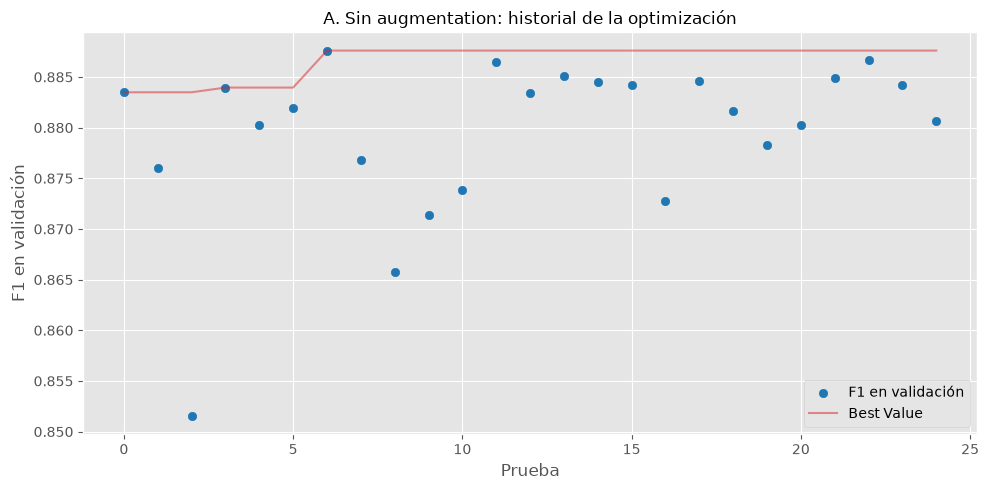

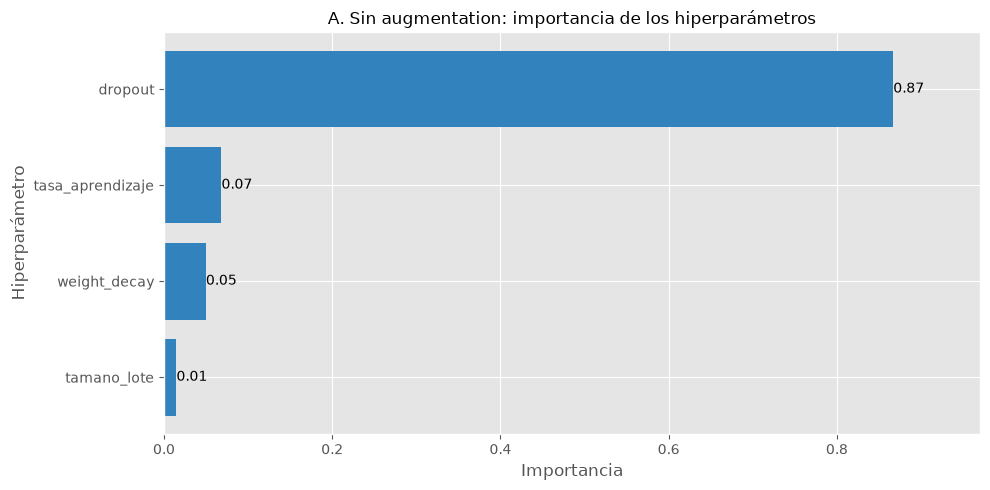

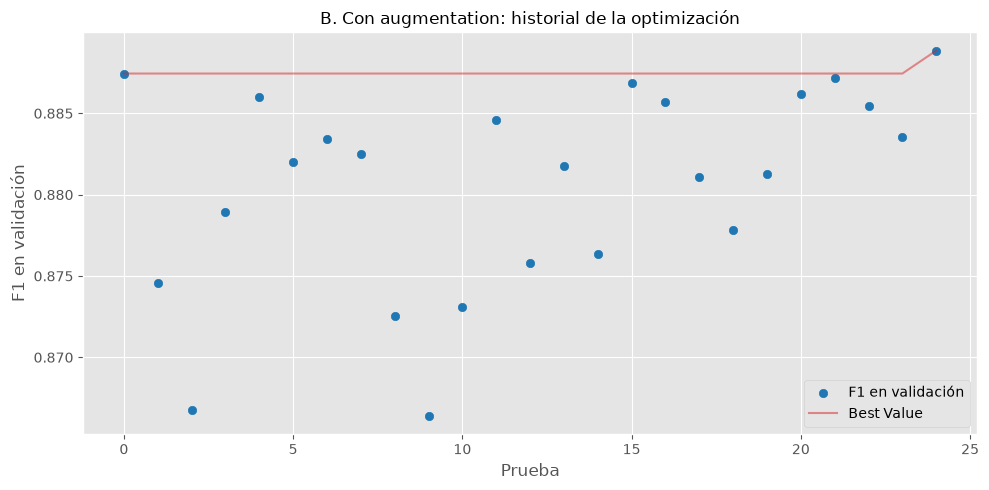

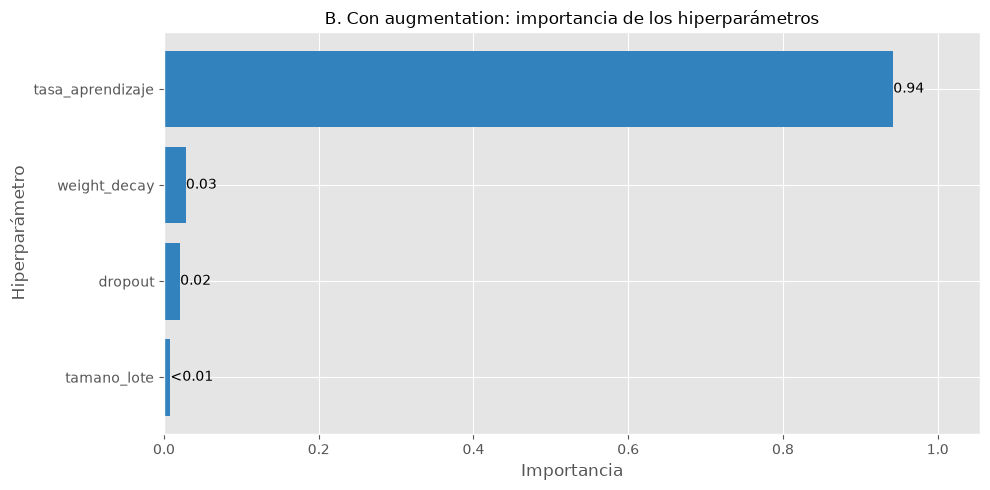

In [34]:
# ------------------------------------------------------------
# 7.2 Historial de la optimización e importancia de cada hiperparámetro
# ------------------------------------------------------------
# Historial: F1 de cada prueba y el mejor valor alcanzado hasta ese momento.
# Importancia: qué tanto influyó cada hiperparámetro en el resultado.

for nombre, estudio in estudios.items():

    # Historial de la optimización
    eje = plot_optimization_history(estudio, target_name="F1 en validación")
    eje.figure.set_size_inches(10, 5)
    eje.set_title("", loc="left")   # quita el título que Optuna pone por defecto
    eje.set_title(f"{nombre}: historial de la optimización", fontsize=12)
    eje.set_xlabel("Prueba")
    eje.legend(loc="lower right")   # pasa la leyenda adentro de la gráfica
    eje.figure.tight_layout()
    plt.show()

    # Importancia de los hiperparámetros
    eje = plot_param_importances(estudio)
    eje.figure.set_size_inches(10, 5)
    eje.set_title("", loc="left")   # quita el título que Optuna pone por defecto
    eje.set_title(f"{nombre}: importancia de los hiperparámetros", fontsize=12)
    eje.set_xlabel("Importancia")
    eje.set_ylabel("Hiperparámetro")
    eje.get_legend().remove()       # la leyenda no aporta nada en esta gráfica
    eje.figure.tight_layout()
    plt.show()

En las gráficas de importancia se observa que el hiperparámetro que más influyó fue distinto en cada modelo, ya que en el modelo A fue el dropout, con una importancia de 0.87, mientras que en el modelo B fue la tasa de aprendizaje, con 0.94, y en ambos casos el tamaño de lote prácticamente no tuvo efecto. Esto indica que en una siguiente optimización convendría concentrar la búsqueda en la tasa de aprendizaje y el dropout, y dejar fijo el tamaño de lote.

In [35]:
# ------------------------------------------------------------
# 7.3 Entrenamiento final con los mejores hiperparámetros
# ------------------------------------------------------------

MEJORES_PARAMETROS = {}
for nombre, estudio in estudios.items():
    MEJORES_PARAMETROS[nombre] = estudio.best_params

X_a, y_a = DATOS_MODELOS["A. Sin augmentation"]
cabeza_a, historial_a = entrenar_cabeza(X_a, y_a, "A. Sin augmentation", MEJORES_PARAMETROS["A. Sin augmentation"])

X_b, y_b = DATOS_MODELOS["B. Con augmentation"]
cabeza_b, historial_b = entrenar_cabeza(X_b, y_b, "B. Con augmentation", MEJORES_PARAMETROS["B. Con augmentation"])

A. Sin augmentation: early stopping en la época 19
A. Sin augmentation: 12000 vectores de entrenamiento | mejor época: 14 | F1 en validación: 88.76%
B. Con augmentation: early stopping en la época 19
B. Con augmentation: 36000 vectores de entrenamiento | mejor época: 14 | F1 en validación: 88.89%


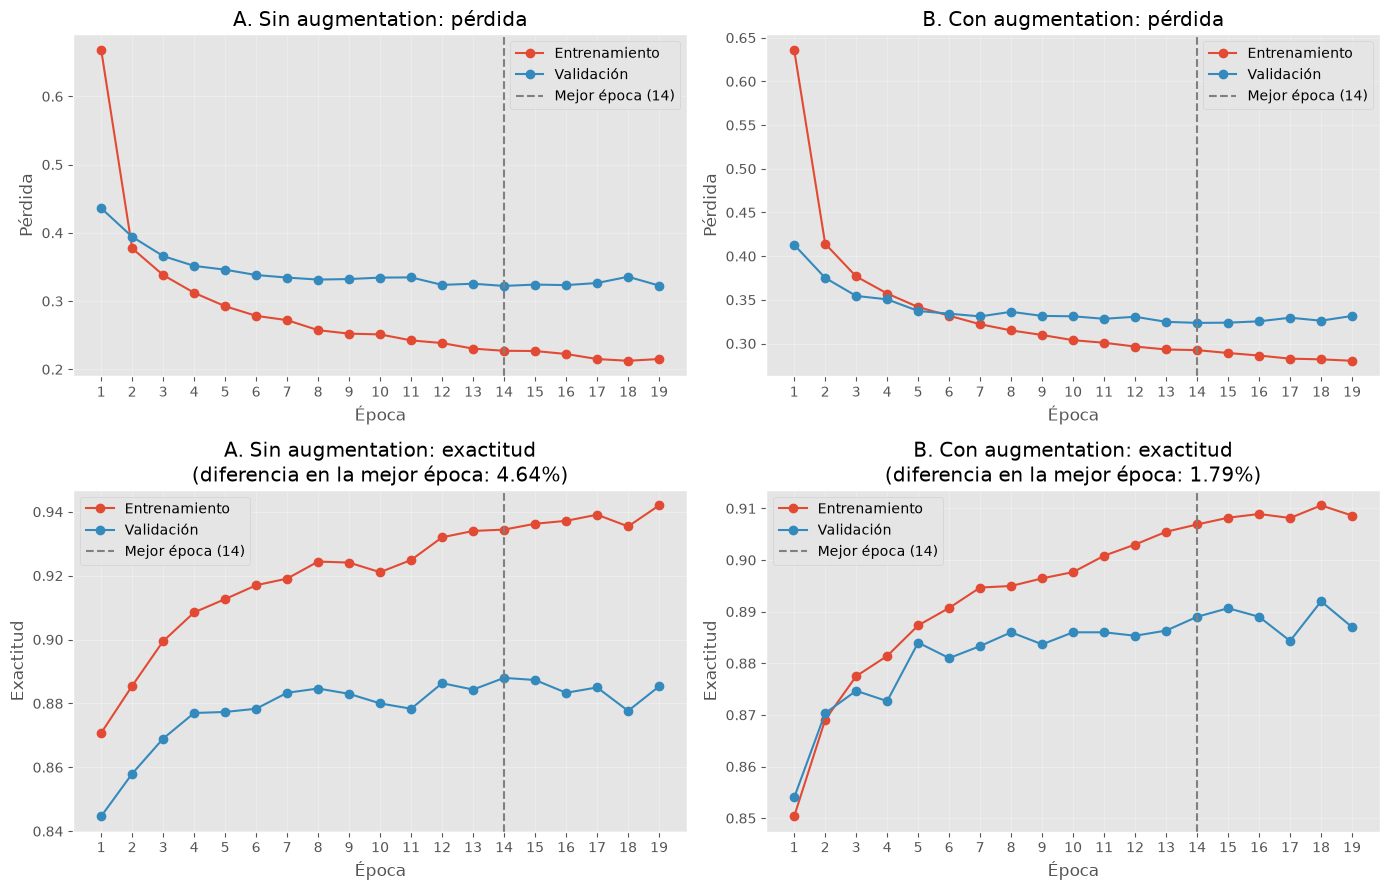

In [36]:
# ------------------------------------------------------------
# 7.4 Curvas de entrenamiento
# ------------------------------------------------------------
# Por cada modelo se compara entrenamiento contra validación, en pérdida y en exactitud;
# si las curvas se separan mucho, el modelo está memorizando el entrenamiento (sobreajuste).
# La línea punteada marca la época que se conservó por el early stopping.

plt.figure(figsize=(14, 9))

posicion = 1
for historial in [historial_a, historial_b]:
    nombre = historial["modelo"].iloc[0]
    epocas = historial["epoca"]
    mejor_epoca = historial.loc[historial["perdida_validacion"].idxmin(), "epoca"]
    fila_mejor = historial[historial["epoca"] == mejor_epoca].iloc[0]
    diferencia = fila_mejor["exactitud_entrenamiento"] - fila_mejor["exactitud_validacion"]

    # Pérdida de entrenamiento contra validación
    plt.subplot(2, 2, posicion)
    plt.plot(epocas, historial["perdida"], marker="o", label="Entrenamiento")
    plt.plot(epocas, historial["perdida_validacion"], marker="o", label="Validación")
    plt.axvline(mejor_epoca, color="gray", linestyle="--", label=f"Mejor época ({mejor_epoca})")
    plt.title(f"{nombre}: pérdida")
    plt.xlabel("Época")
    plt.ylabel("Pérdida")
    plt.xticks(range(1, len(epocas) + 1))
    plt.legend()
    plt.grid(alpha=0.3)

    # Exactitud de entrenamiento contra validación
    plt.subplot(2, 2, posicion + 2)
    plt.plot(epocas, historial["exactitud_entrenamiento"], marker="o", label="Entrenamiento")
    plt.plot(epocas, historial["exactitud_validacion"], marker="o", label="Validación")
    plt.axvline(mejor_epoca, color="gray", linestyle="--", label=f"Mejor época ({mejor_epoca})")
    plt.title(f"{nombre}: exactitud\n(diferencia en la mejor época: {diferencia:.2%})")
    plt.xlabel("Época")
    plt.ylabel("Exactitud")
    plt.xticks(range(1, len(epocas) + 1))
    plt.legend()
    plt.grid(alpha=0.3)

    posicion += 1

plt.tight_layout()
plt.show()

En ambos modelos el early stopping detuvo el entrenamiento en la época 19 y conservó los pesos de la época 14. En el modelo A la pérdida de validación baja muy poco a partir de la época 6 mientras la de entrenamiento sigue bajando, lo que deja una diferencia de 4.64% entre la exactitud de entrenamiento y la de validación en la mejor época, es decir, el modelo empieza a memorizar las imágenes de entrenamiento. En cambio, en el modelo B las dos curvas de pérdida se mantienen casi juntas durante todo el entrenamiento y la diferencia en exactitud baja a 1.79%, por lo que el data augmentation sí ayudó a reducir el sobreajuste.

In [37]:
# ------------------------------------------------------------
# 8. Selección del modelo con el conjunto de validación
# ------------------------------------------------------------
# Se compara cada modelo en validación normal y en validación perturbada.
# El puntaje es el promedio de ambos F1, para premiar al modelo que además de acertar
# es robusto ante imágenes con variaciones como las de una foto real.

modelos = {
    "A. Sin augmentation": cabeza_a,
    "B. Con augmentation": cabeza_b,
}

seleccion = []
for nombre, cabeza in modelos.items():
    f1_normal = f1_score(y_validacion, predecir(cabeza, X_validacion), average="macro")
    f1_perturbada = f1_score(y_validacion, predecir(cabeza, X_validacion_perturbada), average="macro")
    seleccion.append({
        "modelo": nombre,
        "f1_validacion": f1_normal,
        "f1_validacion_perturbada": f1_perturbada,
        "puntaje": (f1_normal + f1_perturbada) / 2,
    })

seleccion = pd.DataFrame(seleccion).sort_values("puntaje", ascending=False).reset_index(drop=True)

# Se elige automáticamente el modelo con mayor puntaje
MODELO_ELEGIDO = seleccion.loc[0, "modelo"]
cabeza_final = modelos[MODELO_ELEGIDO]
print(f"Modelo elegido: {MODELO_ELEGIDO}")

seleccion.round(4)

Modelo elegido: B. Con augmentation


,modelo,f1_validacion,f1_validacion_perturbada,puntaje
0,B. Con augmentation,0.8889,0.8026,0.8457
1,A. Sin augmentation,0.8876,0.6923,0.7900


El modelo B tiene un F1 en validación ligeramente mayor (88.89% contra 88.76%), y la diferencia se vuelve mucho más clara con las imágenes perturbadas, ya que el F1 del modelo B se mantiene en 80.26% mientras que el del modelo A cae a 69.23%. Por lo tanto, el modelo B obtiene el mejor puntaje (0.8457 contra 0.7900) y es el que se usa en el chatbot, ya que las fotos que envía un cliente rara vez van a estar tan centradas y limpias como las de Fashion-MNIST.

In [38]:
# ------------------------------------------------------------
# 9. Evaluación del modelo visual
# ------------------------------------------------------------

def metricas(conjunto, real, pred):
    """
    Calcula accuracy, precisión, recall y F1 macro de un conjunto.
    """
    return {
        "conjunto": conjunto,
        "imagenes": len(real),
        "accuracy": accuracy_score(real, pred),
        "precision_macro": precision_score(real, pred, average="macro", zero_division=0),
        "recall_macro": recall_score(real, pred, average="macro", zero_division=0),
        "f1_macro": f1_score(real, pred, average="macro", zero_division=0),
    }

pred_entrenamiento = predecir(cabeza_final, X_entrenamiento)
pred_validacion = predecir(cabeza_final, X_validacion)
pred_validacion_perturbada = predecir(cabeza_final, X_validacion_perturbada)
pred_prueba = predecir(cabeza_final, X_prueba)
pred_prueba_perturbada = predecir(cabeza_final, X_prueba_perturbada)

metricas_visual = pd.DataFrame([
    metricas("Entrenamiento", y_entrenamiento, pred_entrenamiento),
    metricas("Validación", y_validacion, pred_validacion),
    metricas("Validación perturbada", y_validacion, pred_validacion_perturbada),
    metricas("Prueba", y_prueba, pred_prueba),
    metricas("Prueba perturbada", y_prueba, pred_prueba_perturbada),
])

print("Resultados del modelo visual")
print("------------------------")
print(f"Modelo: {MODELO_ELEGIDO}")
print(f"Accuracy en prueba: {accuracy_score(y_prueba, pred_prueba):.2%}")
print(f"F1 macro en prueba: {f1_score(y_prueba, pred_prueba, average='macro'):.2%}")

metricas_visual.round(4)

Resultados del modelo visual
------------------------
Modelo: B. Con augmentation
Accuracy en prueba: 88.88%
F1 macro en prueba: 88.83%


,conjunto,imagenes,accuracy,precision_macro,recall_macro,f1_macro
0,Entrenamiento,12000,0.9214,0.9212,0.9214,0.9209
1,Validación,3000,0.8890,0.8899,0.8890,0.8889
2,Validación perturbada,3000,0.8020,0.8047,0.8020,0.8026
3,Prueba,10000,0.8888,0.8887,0.8888,0.8883
4,Prueba perturbada,10000,0.8197,0.8204,0.8197,0.8197


En el conjunto de prueba, que el modelo no vio en ningún momento, se obtuvo un accuracy de 88.88% y un F1 macro de 88.83%, valores muy parecidos a los de validación (88.90% y 88.89%), lo que indica que el modelo generaliza bien a imágenes nuevas. Con las imágenes perturbadas el accuracy baja a 81.97%, por lo que el modelo pierde alrededor de 7 puntos cuando la prenda está girada, descentrada o con otra iluminación.

In [39]:
# ------------------------------------------------------------
# 9.1 Comparación de los dos modelos en prueba
# ------------------------------------------------------------
# Solo como referencia, ya que el modelo se eligió con validación

comparacion_prueba = []
for nombre, cabeza in modelos.items():
    pred = predecir(cabeza, X_prueba)
    pred_perturbada = predecir(cabeza, X_prueba_perturbada)
    comparacion_prueba.append({
        "modelo": nombre,
        "accuracy_prueba": accuracy_score(y_prueba, pred),
        "f1_prueba": f1_score(y_prueba, pred, average="macro"),
        "accuracy_prueba_perturbada": accuracy_score(y_prueba, pred_perturbada),
        "f1_prueba_perturbada": f1_score(y_prueba, pred_perturbada, average="macro"),
        "elegido": nombre == MODELO_ELEGIDO,
    })

pd.DataFrame(comparacion_prueba).round(4)

,modelo,accuracy_prueba,f1_prueba,accuracy_prueba_perturbada,f1_prueba_perturbada,elegido
0,A. Sin augmentation,0.8865,0.8863,0.6903,0.6923,False
1,B. Con augmentation,0.8888,0.8883,0.8197,0.8197,True


En prueba se repite lo que se vio en validación, ya que con imágenes normales los dos modelos tienen un accuracy muy parecido (88.65% el modelo A y 88.88% el modelo B), pero con imágenes perturbadas el modelo B alcanza 81.97% contra 69.03% del modelo A, lo cual confirma que la elección hecha con validación fue la correcta.

In [40]:
# ------------------------------------------------------------
# 9.2 Desempeño por clase en el conjunto de prueba
# ------------------------------------------------------------
reporte = classification_report(y_prueba, pred_prueba, target_names=CLASES, output_dict=True, zero_division=0)
f1_perturbada = f1_score(y_prueba, pred_prueba_perturbada, average=None)

desempeno_clase = []
for i, clase in enumerate(CLASES):
    desempeno_clase.append({
        "clase": clase,
        "prenda_chatbot": CLASE_A_PRENDA[clase],
        "precision": reporte[clase]["precision"],
        "recall": reporte[clase]["recall"],
        "f1": reporte[clase]["f1-score"],
        "f1_perturbada": f1_perturbada[i],
        "imagenes": reporte[clase]["support"],
    })

# Ordenado de menor a mayor F1 para ver primero las clases más difíciles
pd.DataFrame(desempeno_clase).sort_values("f1").reset_index(drop=True).round(3)

,clase,prenda_chatbot,precision,recall,f1,f1_perturbada,imagenes
0,Shirt,shirt,0.721,0.655,0.687,0.537,1000.0
1,Coat,jacket,0.790,0.880,0.833,0.676,1000.0
2,T-shirt/top,shirt,0.832,0.834,0.833,0.773,1000.0
3,Pullover,jacket,0.842,0.845,0.844,0.772,1000.0
4,Dress,dress,0.874,0.866,0.870,0.799,1000.0
5,Sneaker,shoes,0.929,0.947,0.938,0.881,1000.0
6,Ankle boot,shoes,0.958,0.949,0.953,0.921,1000.0
7,Sandal,shoes,0.966,0.961,0.963,0.915,1000.0
8,Bag,accessories,0.983,0.979,0.981,0.957,1000.0
9,Trouser,pants,0.991,0.972,0.981,0.967,1000.0


Las clases con peor desempeño son Shirt (F1 de 0.687), T-shirt/top y Coat (0.833) y Pullover (0.844), que son prendas de la parte superior con siluetas muy parecidas, mientras que Bag, Trouser, Sandal y Ankle boot superan 0.95 por tener formas mucho más distintivas. Shirt es también la clase que más sufre con las imágenes perturbadas, ya que su F1 baja a 0.537. Además, Coat tiene un recall mayor que su precisión (0.880 contra 0.790), es decir, el modelo detecta casi todos los abrigos, pero también marca como abrigo a varias camisas y suéteres.

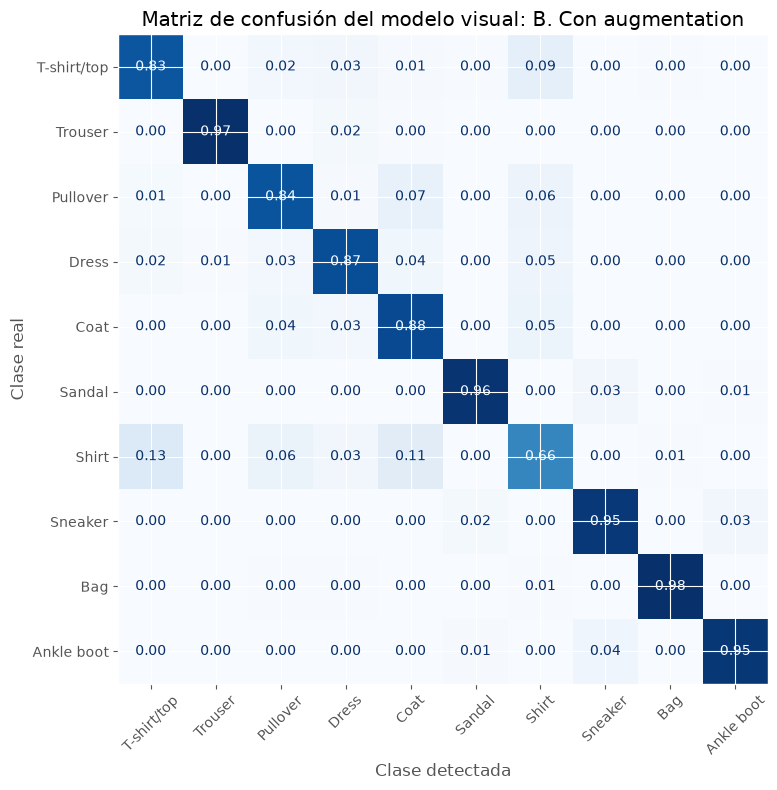

,clase_real,clase_detectada,imagenes
0,Shirt,T-shirt/top,131
1,Shirt,Coat,109
2,T-shirt/top,Shirt,89
3,Pullover,Coat,74
4,Shirt,Pullover,64
5,Pullover,Shirt,56
6,Coat,Shirt,50
7,Dress,Shirt,49


In [41]:
# ------------------------------------------------------------
# 9.3 Matriz de confusión
# ------------------------------------------------------------
# Filas: clase real | Columnas: clase detectada, normalizada por fila

matriz = confusion_matrix(y_prueba, pred_prueba, normalize="true")

fig, ax = plt.subplots(figsize=(9, 8))
ConfusionMatrixDisplay(matriz, display_labels=CLASES).plot(
    ax=ax, cmap="Blues", xticks_rotation=45, values_format=".2f", colorbar=False)
ax.set_title(f"Matriz de confusión del modelo visual: {MODELO_ELEGIDO}")
ax.set_xlabel("Clase detectada")
ax.set_ylabel("Clase real")
plt.tight_layout()
plt.savefig("matriz_confusion_visual.png", dpi=150)
plt.show()

# Pares de clases que más se confunden
confusiones = []
for real, detectada in zip(y_prueba, pred_prueba):
    if real != detectada:
        confusiones.append({"clase_real": CLASES[real], "clase_detectada": CLASES[detectada]})

confusiones = pd.DataFrame(confusiones)
(confusiones.groupby(["clase_real", "clase_detectada"]).size()
 .sort_values(ascending=False).head(8).reset_index(name="imagenes"))

La matriz de confusión confirma que los errores se concentran entre las prendas superiores, siendo las confusiones más frecuentes Shirt detectada como T-shirt/top (131 imágenes), Shirt detectada como Coat (109) y T-shirt/top detectada como Shirt (89). El calzado casi no se confunde con el resto de las prendas, y los pocos errores que tiene son entre Sneaker, Sandal y Ankle boot.

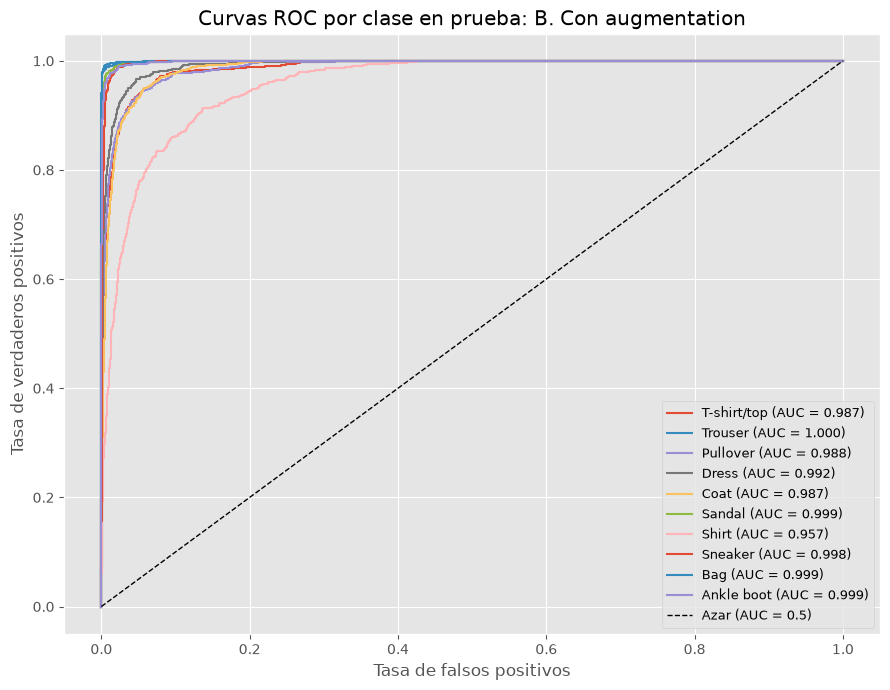

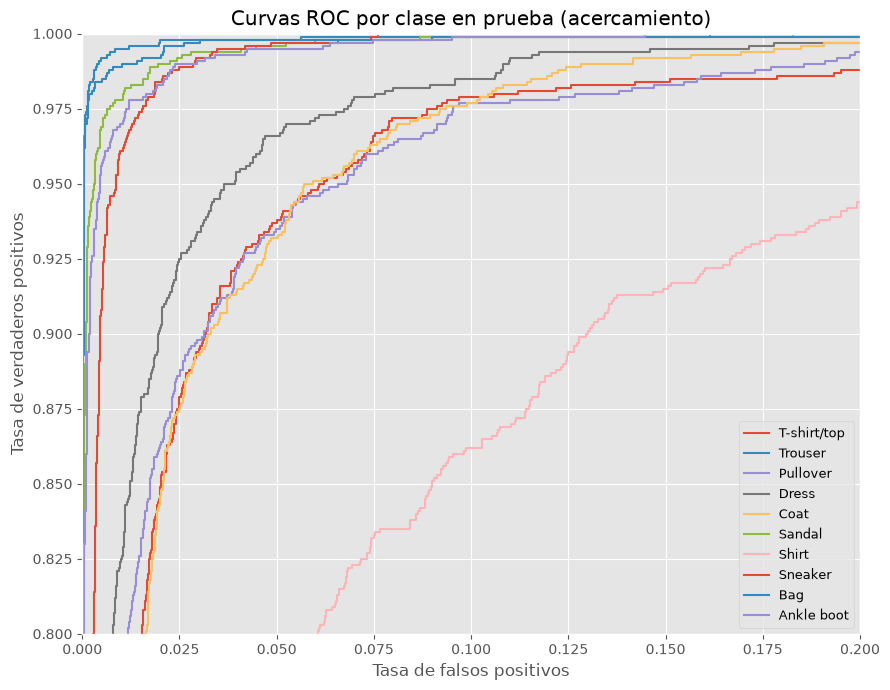

AUC macro en prueba: 0.9904
AUC macro en prueba perturbada: 0.9806


,clase,auc_prueba,auc_prueba_perturbada
6,Shirt,0.9567,0.9254
4,Coat,0.9869,0.9643
0,T-shirt/top,0.9871,0.9768
2,Pullover,0.9875,0.9755
3,Dress,0.9917,0.9824
7,Sneaker,0.9977,0.9937
9,Ankle boot,0.9986,0.9955
5,Sandal,0.9990,0.9964
8,Bag,0.9994,0.9981
1,Trouser,0.9995,0.9982


In [42]:
# ------------------------------------------------------------
# 9.3.1 Curvas ROC y AUC
# ------------------------------------------------------------
# Como son 10 clases se usa el esquema uno contra el resto: para cada clase se toma
# la probabilidad que el modelo le asigna y se compara contra todas las demás clases.
# La curva ROC muestra la tasa de verdaderos positivos contra la de falsos positivos
# al mover el umbral, y el AUC resume la curva en un número entre 0.5 (azar) y 1 (perfecto).

from sklearn.metrics import roc_curve, roc_auc_score, auc
from sklearn.preprocessing import label_binarize

def predecir_probabilidades(cabeza, X):
    """
    Devuelve la probabilidad de cada una de las 10 clases para cada vector de características.
    """
    cabeza.eval()
    with torch.no_grad():
        salida = cabeza(X.to(DISPOSITIVO))
    return torch.softmax(salida, dim=1).cpu().numpy()

prob_prueba = predecir_probabilidades(cabeza_final, X_prueba)
prob_prueba_perturbada = predecir_probabilidades(cabeza_final, X_prueba_perturbada)

# Cada etiqueta se convierte en un vector de 10 posiciones con un 1 en su clase
y_prueba_binaria = label_binarize(y_prueba, classes=list(range(len(CLASES))))

# Curva ROC de cada clase en el conjunto de prueba
plt.figure(figsize=(9, 7))
for i, clase in enumerate(CLASES):
    fpr, tpr, _ = roc_curve(y_prueba_binaria[:, i], prob_prueba[:, i])
    plt.plot(fpr, tpr, linewidth=1.5, label=f"{clase} (AUC = {auc(fpr, tpr):.3f})")

plt.plot([0, 1], [0, 1], "k--", linewidth=1, label="Azar (AUC = 0.5)")
plt.xlabel("Tasa de falsos positivos")
plt.ylabel("Tasa de verdaderos positivos")
plt.title(f"Curvas ROC por clase en prueba: {MODELO_ELEGIDO}")
plt.legend(loc="lower right", fontsize=9)
plt.tight_layout()
plt.savefig("curvas_roc_visual.png", dpi=150)
plt.show()

# Acercamiento a la esquina superior izquierda, donde se ven las diferencias entre clases
plt.figure(figsize=(9, 7))
for i, clase in enumerate(CLASES):
    fpr, tpr, _ = roc_curve(y_prueba_binaria[:, i], prob_prueba[:, i])
    plt.plot(fpr, tpr, linewidth=1.5, label=clase)

plt.xlim(0, 0.2)
plt.ylim(0.8, 1.0)
plt.xlabel("Tasa de falsos positivos")
plt.ylabel("Tasa de verdaderos positivos")
plt.title("Curvas ROC por clase en prueba (acercamiento)")
plt.legend(loc="lower right", fontsize=9)
plt.tight_layout()
plt.show()

# AUC por clase en prueba y en prueba perturbada
filas_auc = []
for i, clase in enumerate(CLASES):
    filas_auc.append({
        "clase": clase,
        "auc_prueba": roc_auc_score(y_prueba_binaria[:, i], prob_prueba[:, i]),
        "auc_prueba_perturbada": roc_auc_score(y_prueba_binaria[:, i], prob_prueba_perturbada[:, i]),
    })

tabla_auc = pd.DataFrame(filas_auc).sort_values("auc_prueba")

auc_macro = roc_auc_score(y_prueba, prob_prueba, multi_class="ovr", average="macro")
auc_macro_perturbada = roc_auc_score(y_prueba, prob_prueba_perturbada, multi_class="ovr", average="macro")
print(f"AUC macro en prueba: {auc_macro:.4f}")
print(f"AUC macro en prueba perturbada: {auc_macro_perturbada:.4f}")

tabla_auc.round(4)

El AUC macro es de 0.9904 en prueba y de 0.9806 en prueba perturbada, lo que indica que el modelo separa muy bien cada clase del resto al ordenar las imágenes según la probabilidad que les asigna, aun cuando la clase final que elige no siempre sea la correcta. Shirt vuelve a ser la clase más débil con un AUC de 0.9567, seguida de Coat, T-shirt/top y Pullover, mientras que Trouser, Bag y Sandal quedan prácticamente en 1.

In [43]:
# ------------------------------------------------------------
# 9.4 Desempeño por prenda del catálogo del chatbot
# ------------------------------------------------------------
# Varias clases de Fashion-MNIST corresponden a la misma prenda del chatbot
# (por ejemplo Sandal, Sneaker y Ankle boot son shoes), así que se mide también a ese nivel

prenda_real = []
prenda_predicha = []
for real, detectada in zip(y_prueba, pred_prueba):
    prenda_real.append(CLASE_A_PRENDA[CLASES[real]])
    prenda_predicha.append(CLASE_A_PRENDA[CLASES[detectada]])

print("Resultados por prenda del chatbot")
print("------------------------")
print(f"Accuracy: {accuracy_score(prenda_real, prenda_predicha):.2%}")
print(f"F1 macro: {f1_score(prenda_real, prenda_predicha, average='macro'):.2%}")

Resultados por prenda del chatbot
------------------------
Accuracy: 93.59%
F1 macro: 93.28%


Al agrupar las clases en las prendas del catálogo del chatbot el accuracy sube de 88.88% a 93.59%, ya que varias de las confusiones más comunes quedan dentro de la misma prenda, como T-shirt/top y Shirt que ambas corresponden a shirt, o Pullover y Coat que ambas corresponden a jacket. Por lo tanto, para el uso real del chatbot el error es menor que el que se ve a nivel de las 10 clases.

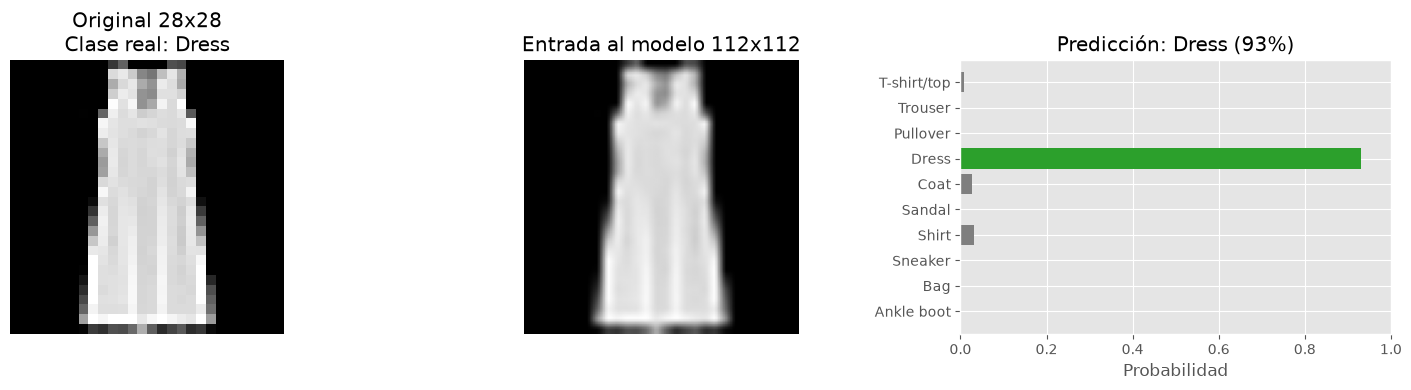

In [44]:
# ------------------------------------------------------------
# 9.5 Visualizador de un ejemplo
# ------------------------------------------------------------
# Muestra una imagen de prueba, cómo la recibe el modelo después del preprocesamiento
# y la probabilidad que le asigna a cada una de las 10 clases.

# Red completa: red base congelada + capa nueva elegida
modelo_completo = nn.Sequential(red_base, cabeza_final).to(DISPOSITIVO)
modelo_completo.eval()

# Índice de la imagen del conjunto de prueba que se quiere revisar (de 0 a 9999)
INDICE_EJEMPLO = 86

imagen_original, clase_real = fashion_prueba[INDICE_EJEMPLO]
imagen_tensor = transformacion_base(imagen_original).unsqueeze(0).to(DISPOSITIVO)

with torch.no_grad():
    salida = modelo_completo(imagen_tensor)
    probabilidades = torch.softmax(salida, dim=1)[0].cpu().numpy()
clase_predicha = probabilidades.argmax()

# Se quita la normalización solo para poder ver la imagen que entra a la red
imagen_entrada = imagen_tensor[0, 0].cpu().numpy() * DESVIACION[0] + MEDIA[0]

# La clase predicha se pinta en verde
colores = []
for i in range(len(CLASES)):
    if i == clase_predicha:
        colores.append("tab:green")
    else:
        colores.append("tab:gray")

plt.figure(figsize=(15, 4))

plt.subplot(1, 3, 1)
plt.imshow(imagen_original, cmap="gray")
plt.title(f"Original 28x28\nClase real: {CLASES[clase_real]}")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(np.clip(imagen_entrada, 0, 1), cmap="gray")
plt.title(f"Entrada al modelo {TAMANO_IMAGEN}x{TAMANO_IMAGEN}")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.barh(CLASES, probabilidades, color=colores)
plt.gca().invert_yaxis()
plt.xlim(0, 1)
plt.xlabel("Probabilidad")
plt.title(f"Predicción: {CLASES[clase_predicha]} ({probabilidades[clase_predicha]:.0%})")

plt.tight_layout()
plt.show()

En el ejemplo revisado el modelo identifica correctamente el vestido con una probabilidad de 93%, y se puede ver cómo la imagen de 28x28 se amplía a 112x112 antes de entrar a la red. Las únicas otras clases con algo de probabilidad son Shirt, Coat y T-shirt/top, que son justamente las prendas con las que más se confunde el modelo.

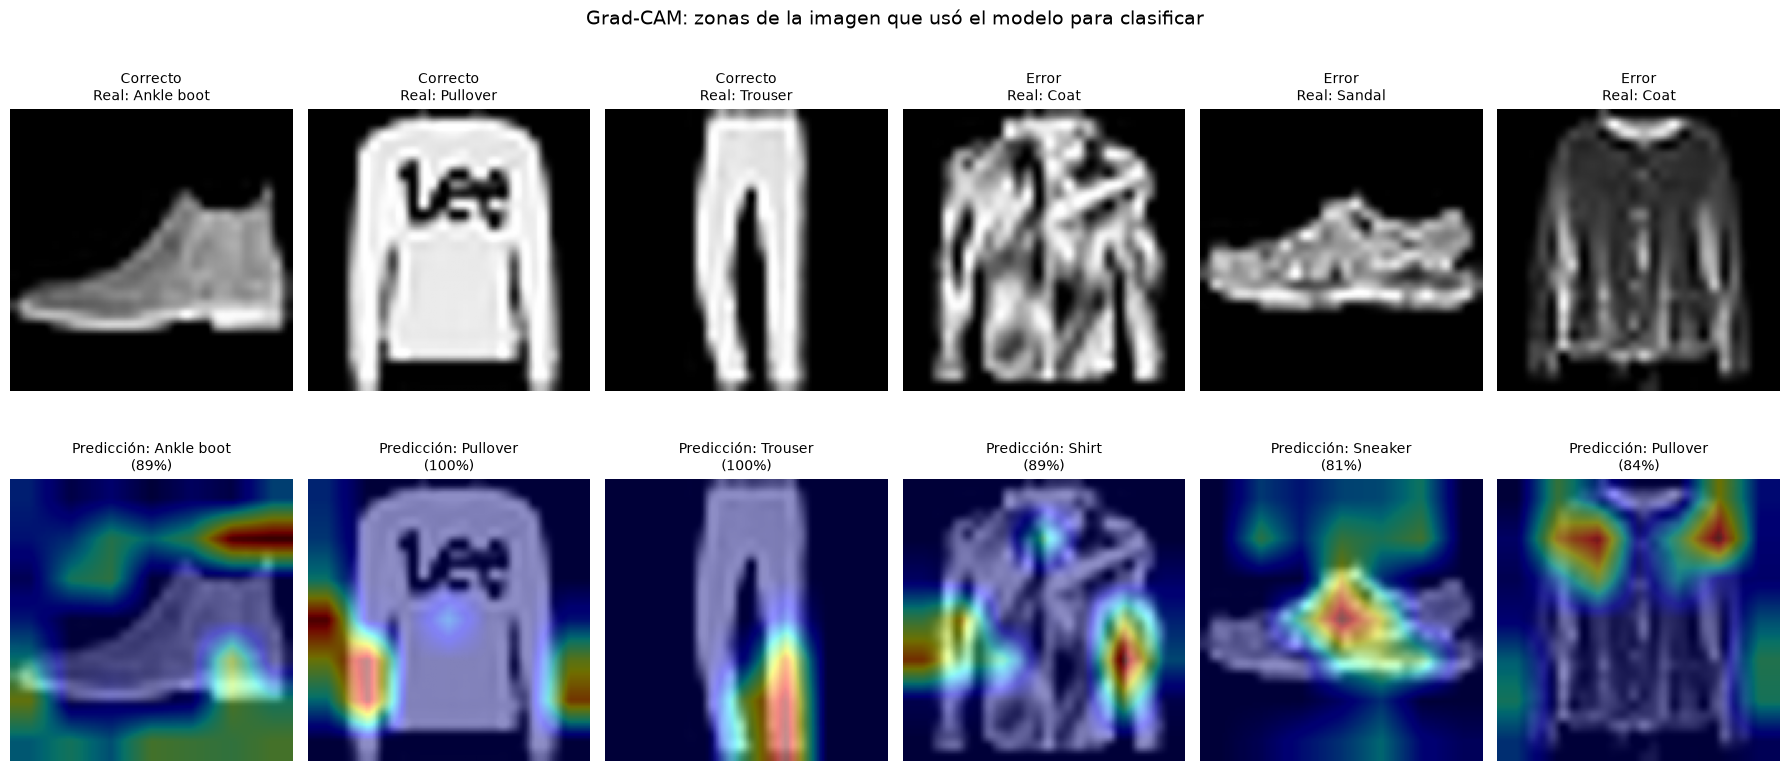

In [45]:
# ------------------------------------------------------------
# 9.6 Mapa de calor con Grad-CAM
# ------------------------------------------------------------
# Grad-CAM indica qué zonas de la imagen pesaron más en la clase que eligió el modelo.
# Usa los gradientes de la clase predicha respecto a una capa convolucional profunda:
# en rojo lo que más influyó en la decisión y en azul lo que casi no importó.
# Se usa la última capa con mapas de 7x7, que da más detalle que la capa final de 4x4.

CAPA_GRADCAM = red_base.features[5]

def grad_cam(imagen_tensor):
    """
    Calcula el mapa de calor de Grad-CAM de una imagen.
    Devuelve el mapa normalizado entre 0 y 1, la clase predicha y su probabilidad.
    """
    capturado = {}

    # Guarda la salida de la capa elegida durante la predicción
    def guardar_activacion(modulo, entrada, salida):
        salida.retain_grad()
        capturado["activacion"] = salida

    gancho = CAPA_GRADCAM.register_forward_hook(guardar_activacion)

    # La red está congelada; se pide el gradiente de la imagen para que se calculen
    # los gradientes de la capa, sin modificar ningún peso del modelo
    entrada = imagen_tensor.clone().requires_grad_(True)
    salida = modelo_completo(entrada)
    gancho.remove()

    probabilidades = torch.softmax(salida, dim=1)[0]
    clase = int(probabilidades.argmax())

    # Gradiente de la clase predicha respecto a la capa
    modelo_completo.zero_grad()
    salida[0, clase].backward()

    activacion = capturado["activacion"][0].detach()
    gradiente = capturado["activacion"].grad[0]

    # Peso de cada mapa = promedio de su gradiente; el mapa final es la suma ponderada
    pesos = gradiente.mean(dim=(1, 2))
    mapa = torch.relu((pesos[:, None, None] * activacion).sum(dim=0))
    mapa = mapa / (mapa.max() + 1e-8)

    # Se amplía el mapa al tamaño de la imagen
    mapa = F.interpolate(mapa[None, None], size=(TAMANO_IMAGEN, TAMANO_IMAGEN),
                         mode="bilinear", align_corners=False)[0, 0]
    return mapa.cpu().numpy(), clase, probabilidades[clase].item()

# Ejemplos: tres bien clasificados de clases distintas y tres mal clasificados
ejemplos_correctos = []
clases_vistas = []
for i in range(len(y_prueba)):
    if pred_prueba[i] == y_prueba[i] and y_prueba[i] not in clases_vistas:
        ejemplos_correctos.append(i)
        clases_vistas.append(y_prueba[i])
    if len(ejemplos_correctos) == 3:
        break

ejemplos_errores = []
for i in range(len(y_prueba)):
    if pred_prueba[i] != y_prueba[i]:
        ejemplos_errores.append(i)
    if len(ejemplos_errores) == 3:
        break

ejemplos = ejemplos_correctos + ejemplos_errores

plt.figure(figsize=(18, 8.5))
for columna, indice in enumerate(ejemplos):
    imagen_original, clase_real = fashion_prueba[indice]
    imagen_tensor = transformacion_base(imagen_original).unsqueeze(0).to(DISPOSITIVO)
    mapa, clase, probabilidad = grad_cam(imagen_tensor)
    imagen_grande = np.array(imagen_original.resize((TAMANO_IMAGEN, TAMANO_IMAGEN)))

    if clase == clase_real:
        tipo = "Correcto"
    else:
        tipo = "Error"

    # Arriba la imagen y abajo la misma imagen con el mapa de calor
    plt.subplot(2, 6, columna + 1)
    plt.imshow(imagen_grande, cmap="gray")
    plt.title(f"{tipo}\nReal: {CLASES[clase_real]}", fontsize=10)
    plt.axis("off")

    plt.subplot(2, 6, columna + 7)
    plt.imshow(imagen_grande, cmap="gray")
    plt.imshow(mapa, cmap="jet", alpha=0.45)
    plt.title(f"Predicción: {CLASES[clase]}\n({probabilidad:.0%})", fontsize=10)
    plt.axis("off")

plt.suptitle("Grad-CAM: zonas de la imagen que usó el modelo para clasificar", fontsize=14)
plt.tight_layout()
plt.savefig("grad_cam_ejemplos.png", dpi=150)
plt.show()

En los ejemplos correctos el mapa de calor se concentra en zonas propias de la prenda, como la parte baja de la pierna en el pantalón o las mangas en el pullover, mientras que en los errores el modelo se fija en detalles que comparten varias prendas, como las mangas en el abrigo que se clasificó como Shirt o los hombros en el abrigo que se clasificó como Pullover, y en la sandalia que se confundió con Sneaker se concentra en el centro del calzado, donde ambas prendas se parecen. También se observa que en algunos casos el mapa marca partes del fondo, como en la bota, lo cual es una limitación de trabajar con imágenes de 28x28 ampliadas y con mapas de 7x7.

In [46]:
# ------------------------------------------------------------
# 10. Guardado del modelo y de imágenes de prueba para el chatbot
# ------------------------------------------------------------

# Se guarda la red completa (red base congelada + capa nueva elegida) para usarla en el chatbot
modelo_completo = modelo_completo.cpu()
torch.save({
    "arquitectura": ARQUITECTURA,
    "modelo_elegido": MODELO_ELEGIDO,
    "tamano_imagen": TAMANO_IMAGEN,
    "clases": CLASES,
    "clase_a_prenda": CLASE_A_PRENDA,
    "hiperparametros": MEJORES_PARAMETROS[MODELO_ELEGIDO],
    "modelo": modelo_completo.state_dict(),
}, "modelo_visual.pt")
print("Modelo guardado en modelo_visual.pt")

# Dos imágenes de prueba de cada clase para simular las fotos que enviaría un cliente
os.makedirs("imagenes_prueba", exist_ok=True)
for clase in range(len(CLASES)):
    nombre_archivo = CLASES[clase].replace("/", "_").replace(" ", "_").lower()
    indices_clase = np.where(etiquetas_prueba == clase)[0][:2]
    for n, indice in enumerate(indices_clase, start=1):
        imagen, _ = fashion_prueba[indice]
        imagen.save(f"imagenes_prueba/{nombre_archivo}_{n}.png")

print(f"Imágenes de prueba guardadas: {len(os.listdir('imagenes_prueba'))}")

Modelo guardado en modelo_visual.pt
Imágenes de prueba guardadas: 20


El modelo guardado en modelo_visual.pt es el modelo B con augmentation sobre EfficientNet-B0, y junto con las 20 imágenes de prueba es lo que se usa en el notebook del chatbot para integrar el componente visual.